In [2]:
import numpy as np, pandas as pd, sys
import matplotlib.pyplot as plt
from pathlib import Path

sys.path.append(str(Path.cwd().parent))
from src.path import RAW_DATA_FILE,RESULT_FIG_DATA

# Đường dẫn file dữ liệu thô


df_raw = pd.read_csv(RAW_DATA_FILE)
RAW_FIG = RESULT_FIG_DATA/"raw"

# Chuẩn hóa nhãn và tính số từ cơ bản trước khi xử lý
df_raw['word_count_raw'] = df_raw['text'].fillna('').apply(lambda x: len(str(x).split()))

print("=== Thống kê dữ liệu thô ===")
print(f"Tổng số dòng: {len(df_raw):,}")
display(df_raw.head())

=== Thống kê dữ liệu thô ===
Tổng số dòng: 44,868


,text,label,prompt_name,source,RDizzl3_seven,word_count_raw
0,Phones\r\n\r\nModern humans today are always o...,0,Phones and driving,persuade_corpus,False,379
1,This essay will explain if drivers should or s...,0,Phones and driving,persuade_corpus,False,366
2,Driving while the use of cellular devices\r\n\...,0,Phones and driving,persuade_corpus,False,178
3,Phones & Driving\r\n\r\nDrivers should not be ...,0,Phones and driving,persuade_corpus,False,212
4,Cell Phone Operation While Driving\r\n\r\nThe ...,0,Phones and driving,persuade_corpus,False,332


FileNotFoundError: [Errno 2] No such file or directory: 'H:\\FPT\\4\\DAP\\Project-19\\AI-Generated-Text-Essay-Detection\\result\\fig\\raw\\raw_label_prompt_dist.png'

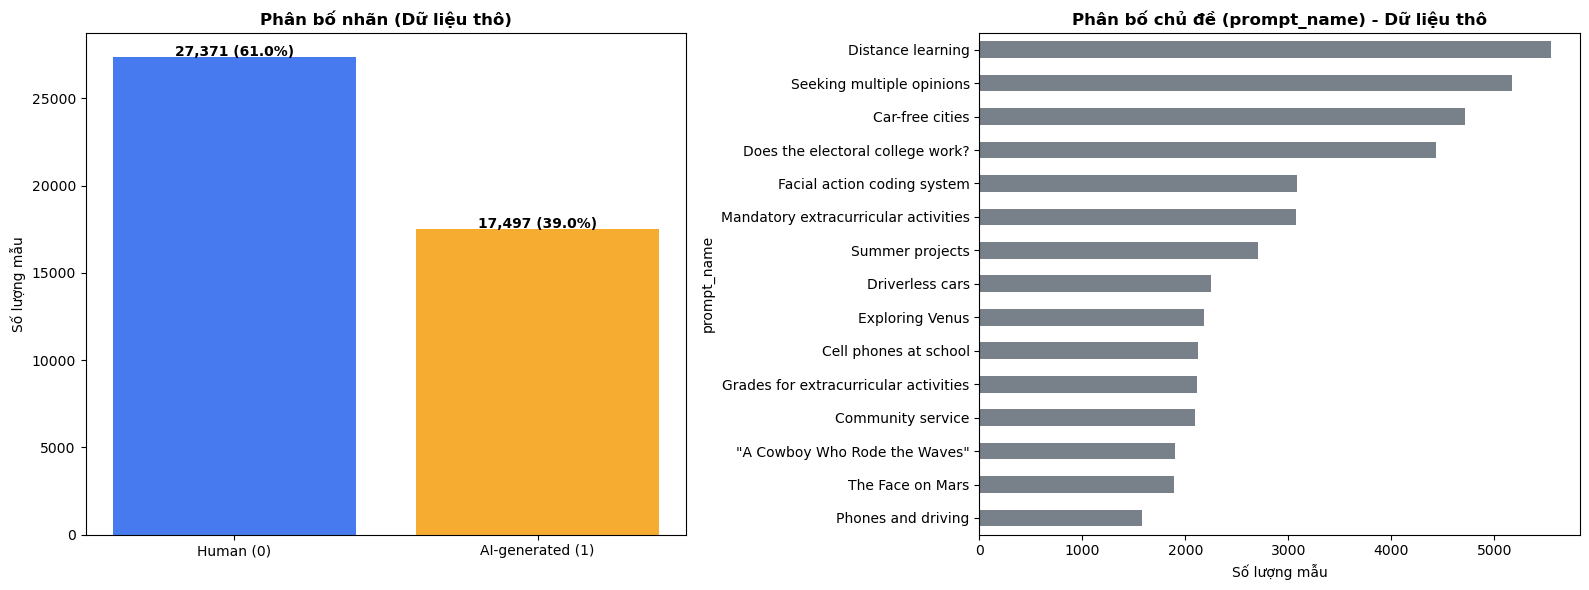

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Phân bố nhãn
label_counts = df_raw['label'].value_counts().sort_index()
bars = axes[0].bar(['Human (0)', 'AI-generated (1)'], label_counts.values, 
                   color=['#2563eb', '#f59e0b'], alpha=0.85)
axes[0].set_title('Phân bố nhãn (Dữ liệu thô)', fontweight='bold')
axes[0].set_ylabel('Số lượng mẫu')
for bar, count in zip(bars, label_counts.values):
    axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 50,
                 f"{count:,} ({count / len(df_raw) * 100:.1f}%)", ha='center', fontweight='bold')

# 2. Phân bố theo chủ đề (prompt_name nếu có)
if 'prompt_name' in df_raw.columns:
    prompt_counts = df_raw['prompt_name'].value_counts().sort_values(ascending=True)
    prompt_counts.plot.barh(ax=axes[1], color='#4b5563', alpha=0.75)
    axes[1].set_title('Phân bố chủ đề (prompt_name) - Dữ liệu thô', fontweight='bold')
    axes[1].set_xlabel('Số lượng mẫu')
else:
    axes[1].text(0.5, 0.5, 'Không có cột prompt_name', ha='center', va='center')

fig.tight_layout()
fig.savefig(RAW_FIG/ 'raw_label_prompt_dist.png', dpi=150, bbox_inches='tight')
plt.show()

,count,mean,median,std,min,max
label,,,,,,
0,27371,418.28,383.0,189.29,143,1656
1,17497,329.40,328.0,94.26,4,818


C:\Users\pc\AppData\Local\Temp\ipykernel_22312\1112223458.py:22: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[1].boxplot(box_data, labels=['Human (0)', 'AI-generated (1)'],


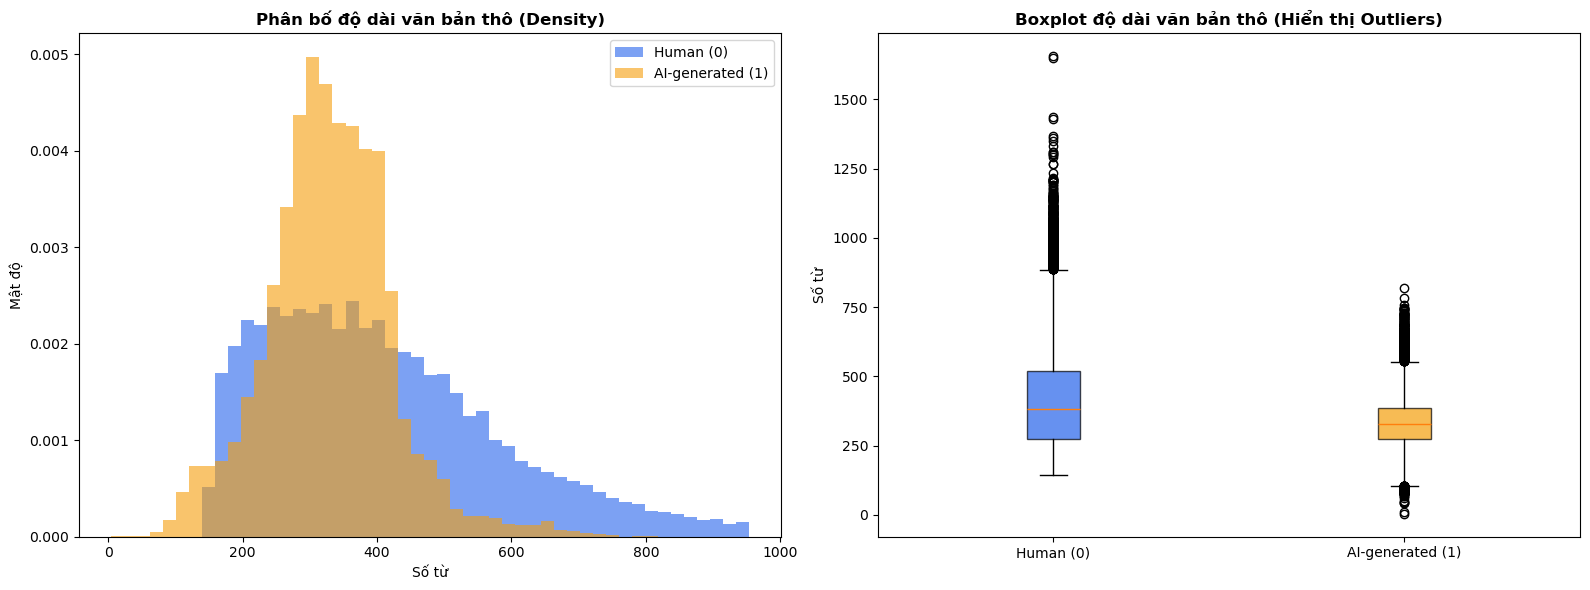

In [ ]:
# Bảng thống kê độ dài văn bản thô theo nhãn
raw_length_stats = df_raw.groupby('label')['word_count_raw'].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
).round(2)
display(raw_length_stats)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Histogram độ dài (hiển thị cả dải giá trị cực trị)
bins = np.linspace(df_raw['word_count_raw'].min(), df_raw['word_count_raw'].quantile(0.99), 50)
for label, color, name in [(0, '#2563eb', 'Human (0)'), (1, '#f59e0b', 'AI-generated (1)')]:
    subset = df_raw[df_raw['label'] == label]['word_count_raw']
    axes[0].hist(subset, bins=bins, alpha=0.6, density=True, label=name, color=color)
axes[0].set_title('Phân bố độ dài văn bản thô (Density)', fontweight='bold')
axes[0].set_xlabel('Số từ')
axes[0].set_ylabel('Mật độ')
axes[0].legend()

# Boxplot giữ nguyên outlier (showfliers=True) để thấy dữ liệu nhiễu/lỗi trước khi clean
box_data = [df_raw[df_raw['label'] == 0]['word_count_raw'], 
            df_raw[df_raw['label'] == 1]['word_count_raw']]
bp = axes[1].boxplot(box_data, labels=['Human (0)', 'AI-generated (1)'], 
                     showfliers=True, patch_artist=True)
for patch, color in zip(bp['boxes'], ['#2563eb', '#f59e0b']):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
axes[1].set_title('Boxplot độ dài văn bản thô (Hiển thị Outliers)', fontweight='bold')
axes[1].set_ylabel('Số từ')

fig.tight_layout()
fig.savefig(RAW_FIG/ 'raw_text_length_boxplot.png', dpi=150, bbox_inches='tight')
df_raw = df_raw.drop('word_count_raw',axis= 1)
plt.show()